# Отрисовка дя визуальной проверки

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import base64
from io import BytesIO

plt.style.use('dark_background')

df = pd.read_csv('dataset_mobile_v2.csv') 

TARGET_LABEL = 2  # 1 - жест 1, 2 - жест 2, 0 - Шум

class_df = df[df['label'] == TARGET_LABEL]
gesture_ids = class_df['gesture_id'].unique()

html = f"""
<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>Класс {TARGET_LABEL}</title>
    <style>
        body {{ background-color: #111; color: white; font-family: sans-serif; padding: 20px; }}
        h1 {{ text-align: center; color: #eccc68; margin-bottom: 30px; }}
        .grid {{ display: grid; grid-template-columns: repeat(auto-fill, minmax(250px, 1fr)); gap: 20px; }}
        .card {{ background: #222; border-radius: 10px; padding: 15px; text-align: center; box-shadow: 0 4px 6px rgba(0,0,0,0.3); }}
        .id-label {{ font-size: 28px; font-weight: bold; color: #ff4757; margin-bottom: 10px; }}
        img {{ max-width: 100%; border-radius: 5px; }}
    </style>
</head>
<body>
    <h1>Класс {TARGET_LABEL}</h1>
    <div class="grid">
"""

for gid in gesture_ids:
    group = class_df[class_df['gesture_id'] == gid]
    
    sx = group['x'].rolling(1, min_periods=1).mean()
    sy = group['y'].rolling(1, min_periods=1).mean()
    sz = group['z'].rolling(1, min_periods=1).mean()
    
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(sx.values, color='#ff4757', linewidth=2) # X - красный
    ax.plot(sy.values, color='#2ed573', linewidth=2) # Y - зеленый
    ax.plot(sz.values, color='#1e90ff', linewidth=2) # Z - синий
    ax.axis('off') # Выключаем оси, оставляем только чистый паттерн
    
    plt.tight_layout()
    
    buf = BytesIO()
    plt.savefig(buf, format='png', facecolor='#222', bbox_inches='tight')
    plt.close(fig)
    img_base64 = base64.b64encode(buf.getbuffer()).decode("ascii")
    
    html += f"""
        <div class="card">
            <div class="id-label">ID: {gid}</div>
            <img src="data:image/png;base64,{img_base64}">
        </div>
    """

html += """
    </div>
</body>
</html>
"""

with open('gallery.html', 'w', encoding='utf-8') as f:
    f.write(html)

print("Файл gallery.htmlсоздан")

Файл gallery.htmlсоздан


# Очистка от мусора

In [35]:
trash_ids = [] # удалить откровенно корявые после пробежки глазками

df_clean = df[~df['gesture_id'].isin(trash_ids)]

# Считаем уникальные идентификаторы жестов
gestures_before = df['gesture_id'].nunique()
gestures_after = df_clean['gesture_id'].nunique()

print(f"Было измерений (жестов): {gestures_before}")
print(f"Осталось измерений (жестов): {gestures_after}")

# Сохраняем чистый датасет
df_clean.to_csv('dataset_mobile_CLEAN.csv', index=False)

Было измерений (жестов): 383
Осталось измерений (жестов): 383


# Аугментация

In [36]:
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
df = pd.read_csv('dataset_mobile_CLEAN.csv')

augmented_rows = []
new_gesture_id = 0

NOISE_LEVEL = 2.0  # Сила фонового шума
SHIFT_MAX = 20     # Максимальный сдвиг

def add_to_dataset(x, y, z, label, gid):
    for i in range(len(x)):
        augmented_rows.append({
            'x': x[i], 'y': y[i], 'z': z[i], 
            'label': label, 'gesture_id': gid
        })

for gid, group in df.groupby('gesture_id'):
    label = group['label'].iloc[0]
    
    x_raw = group['x'].values
    y_raw = group['y'].values
    z_raw = group['z'].values
    n_samples = len(x_raw)
    
    # 0. Убираю фон
    base_len = 10
    x = x_raw - np.mean(x_raw[:base_len])
    y = y_raw - np.mean(y_raw[:base_len])
    z = z_raw - np.mean(z_raw[:base_len])
    
    # Шум 
    # Амплитуда = NOISE_LEVEL. Сглаживание слабое (sigma=1.5), имитирует тремор.
    dyn_noise = lambda: gaussian_filter1d(np.random.normal(0, NOISE_LEVEL, n_samples), sigma=1.1)
    
    # Шум для замещения сдвига
    # Амплитуда = 30% . Сглаживание сильное (sigma=4.0), имитирует медленный дрейф.
    bg_noise = lambda: gaussian_filter1d(np.random.normal(0, NOISE_LEVEL * 0.3, n_samples), sigma=2.0)

    # ==========================================

    # 1. ОРИГИНАЛ (Чистый, с вычетом фона)
    add_to_dataset(x, y, z, label, new_gesture_id)
    new_gesture_id += 1
    
    # 2. ШУМ В ДВИЖЕНИИ (Добавляем шум поверх оригинального сигнала)
    add_to_dataset(x + dyn_noise(), y + dyn_noise(), z + dyn_noise(), label, new_gesture_id)
    new_gesture_id += 1
    
    # 3. МАСШТАБ
    scale_factor = np.random.uniform(0.4, 3)
    add_to_dataset(x * scale_factor, y * scale_factor, z * scale_factor, label, new_gesture_id)
    new_gesture_id += 1
    
    # 4. СДВИГ ПО ВРЕМЕНИ (Пустоты заливаем тихим фоновым шумом)
    shift = np.random.randint(-SHIFT_MAX, SHIFT_MAX)
    
    if shift != 0:
        # Создаем "эфир" покоя
        x_shift, y_shift, z_shift = bg_noise(), bg_noise(), bg_noise()
        
        abs_shift = abs(shift)
        # Врезаем чистый оригинальный жест поверх эфира
        if shift > 0:
            x_shift[shift:] = x[:-shift]
            y_shift[shift:] = y[:-shift]
            z_shift[shift:] = z[:-shift]
        else:
            x_shift[:-abs_shift] = x[abs_shift:]
            y_shift[:-abs_shift] = y[abs_shift:]
            z_shift[:-abs_shift] = z[abs_shift:]
            
        add_to_dataset(x_shift, y_shift, z_shift, label, new_gesture_id)
        new_gesture_id += 1
    else:
        add_to_dataset(x.copy(), y.copy(), z.copy(), label, new_gesture_id)
        new_gesture_id += 1

df_aug = pd.DataFrame(augmented_rows)
df_aug.to_csv('dataset_mobile_AUGMENTED.csv', index=False)

print(f"Исходных жестов: {len(df['gesture_id'].unique())}")
print(f"После аугментации: {len(df_aug['gesture_id'].unique())}")
print("Файл dataset_mobile_AUGMENTED.csv готов!")

Исходных жестов: 383
После аугментации: 1532
Файл dataset_mobile_AUGMENTED.csv готов!


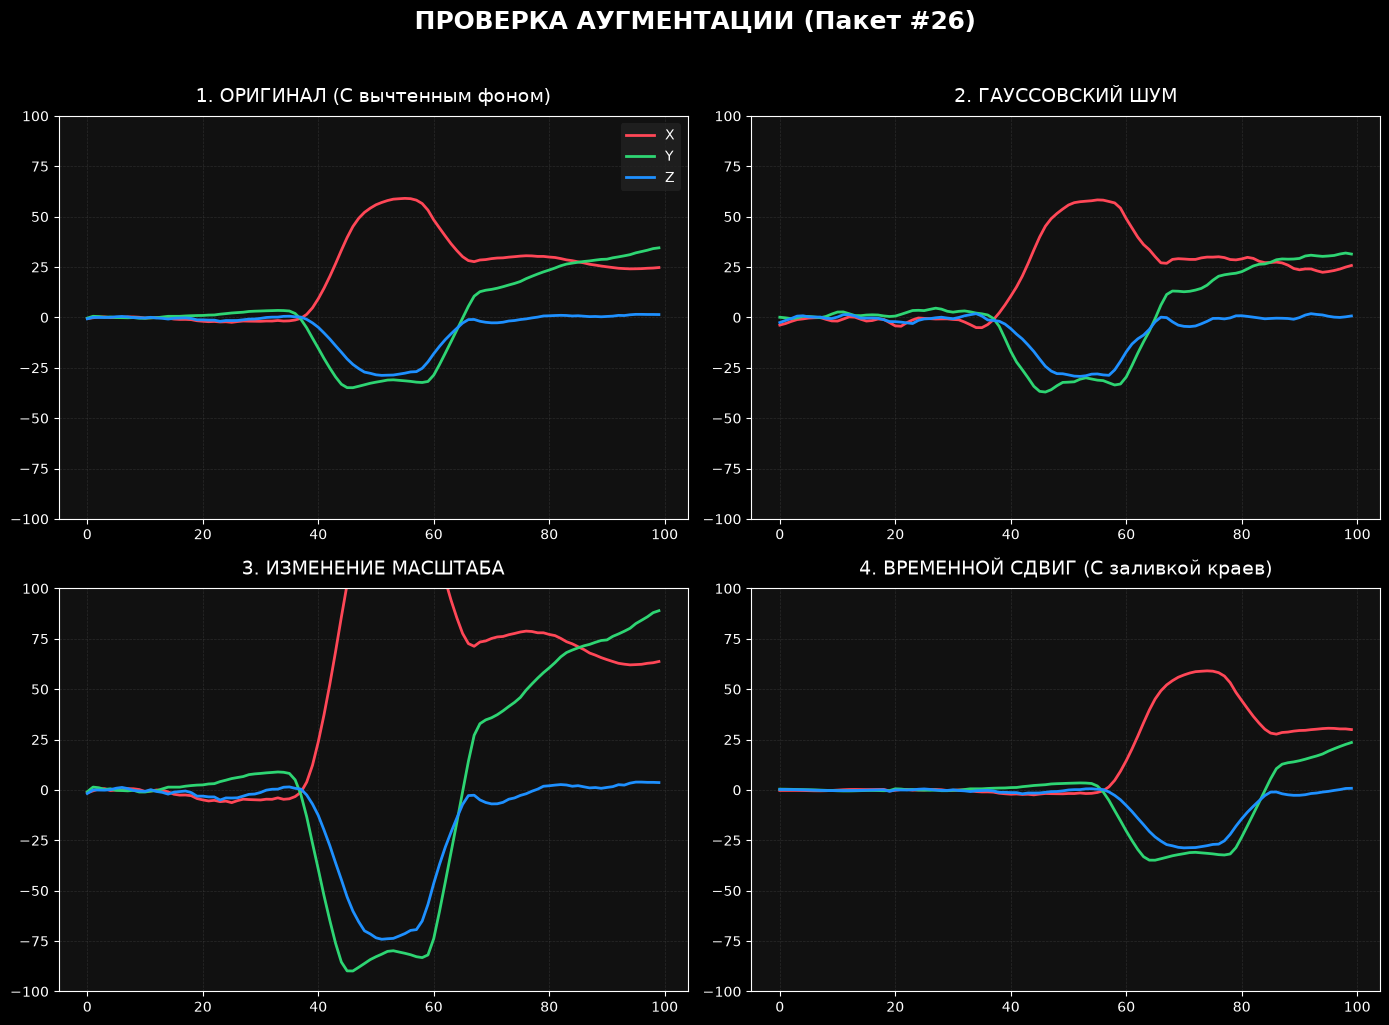

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random

# Темная тема
plt.style.use('dark_background')

# Загружаем аугментации
df_aug = pd.read_csv('dataset_mobile_AUGMENTED.csv')

total_original_gestures = len(df_aug['gesture_id'].unique()) // 4

rand_idx = random.randint(0, total_original_gestures - 1)

base_id = rand_idx * 4
ids_to_plot = [base_id, base_id + 1, base_id + 2, base_id + 3]
titles = [
    '1. ОРИГИНАЛ (С вычтенным фоном)', 
    '2. ГАУССОВСКИЙ ШУМ', 
    '3. ИЗМЕНЕНИЕ МАСШТАБА', 
    '4. ВРЕМЕННОЙ СДВИГ (С заливкой краев)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'ПРОВЕРКА АУГМЕНТАЦИИ (Пакет #{rand_idx})', fontsize=18, fontweight='bold', y=1.02)

for i, ax in enumerate(axes.flatten()):
    group = df_aug[df_aug['gesture_id'] == ids_to_plot[i]]
    if group.empty:
        continue
        
    ax.plot(group['x'].values, color='#ff4757', linewidth=2, label='X')
    ax.plot(group['y'].values, color='#2ed573', linewidth=2, label='Y')
    ax.plot(group['z'].values, color='#1e90ff', linewidth=2, label='Z')
    
    ax.set_title(titles[i], color='white', fontsize=14, pad=10)
    
    # Сетка для наглядности
    ax.grid(color='#444', linestyle='--', linewidth=0.5, alpha=0.5)
    ax.set_ylim(-100, 100)
    ax.set_facecolor('#111')
    
    if i == 0:
        ax.legend(loc='upper right', frameon=True, facecolor='#222', edgecolor='none')

plt.tight_layout()
plt.show()

In [50]:
import torch
import torch.nn as nn
import torch.optim as optim

class EdgeCNN_v4(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels=4, out_channels=16, kernel_size=9, stride=2, padding=2),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),
            
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),
            nn.Flatten()
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5), 
            nn.Linear(32 * 13, 32), # 32 канала * 25 кадров = 800 признаков
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = EdgeCNN_v4(num_classes=3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0003) 

print("Ячейка 4: Модель v4 (4 канала + Flatten) и оптимизатор готовы!")

Ячейка 4: Модель v4 (4 канала + Flatten) и оптимизатор готовы!


In [51]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv('dataset_mobile_AUGMENTED.csv') 

gesture_ids = df['gesture_id'].unique()
X_list, y_list, group_list = [], [], []

for gid in gesture_ids:
    group_data = df[df['gesture_id'] == gid]
    label = group_data['label'].iloc[0]
    base_original_id = gid // 4 
    
    x = group_data['x'].values
    y = group_data['y'].values
    z = group_data['z'].values
    mag = np.sqrt(x**2 + y**2 + z**2)
    
    features = np.vstack([x, y, z, mag])

    if features.shape[1] > 100:
        features = features[:, :100]
    elif features.shape[1] < 100:
        pad_width = 100 - features.shape[1]
        features = np.pad(features, ((0, 0), (0, pad_width)), mode='edge')
        
    features = np.clip(features, -500.0, 500.0) / 500.0
        
    X_list.append(features)
    y_list.append(label)
    group_list.append(base_original_id)

X_all = np.stack(X_list).astype(np.float32)
y_all = np.array(y_list).astype(np.int64)
groups_all = np.array(group_list)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X_all, y_all, groups_all))

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

class MagnetDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

train_dataloader = DataLoader(MagnetDataset(X_train, y_train), batch_size=16, shuffle=True)
val_dataloader = DataLoader(MagnetDataset(X_val, y_val), batch_size=16, shuffle=False)

print(f"Датасет готов! Трейн: {len(X_train)}. Валидация: {len(X_val)}.")

Датасет готов! Трейн: 1224. Валидация: 308.


In [52]:
model = EdgeCNN_v4(num_classes=3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00011) 


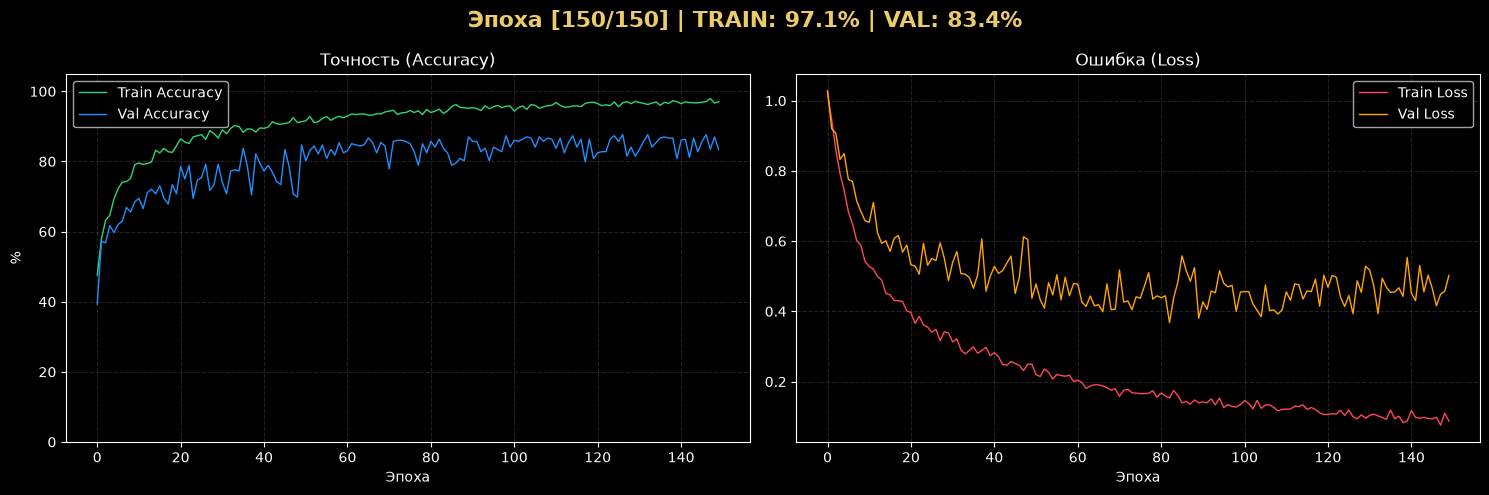

In [53]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

epochs = 150

train_losses, val_losses = [], []
train_accs, val_accs = [], []

plt.style.use('dark_background')

for epoch in range(epochs):

    model.train()
    train_loss = 0
    correct_train = 0
    
    for batch_x, batch_y in train_dataloader:
        optimizer.zero_grad()      
        outputs = model(batch_x)   
        loss = criterion(outputs, batch_y) 
        loss.backward()            
        optimizer.step()           
        
        train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct_train += (predicted == batch_y).sum().item()
        
    acc_train = 100 * correct_train / len(train_dataloader.dataset)
    avg_train_loss = train_loss / len(train_dataloader)


    
    model.eval() 
    val_loss = 0
    correct_val = 0
    
    with torch.no_grad(): 
        for batch_x, batch_y in val_dataloader:
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct_val += (predicted == batch_y).sum().item()
            
    acc_val = 100 * correct_val / len(val_dataloader.dataset)
    avg_val_loss = val_loss / len(val_dataloader)
    
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(acc_train)
    val_accs.append(acc_val)
    

    if (epoch + 1) % 2 == 0 or (epoch + 1) == epochs:
        clear_output(wait=True)
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        fig.suptitle(f'Эпоха [{epoch+1}/{epochs}] | TRAIN: {acc_train:.1f}% | VAL: {acc_val:.1f}%', 
                     fontsize=16, fontweight='bold', color='#eccc68')
        
        # График точности (Accuracy)
        ax1.plot(train_accs, label='Train Accuracy', color='#2ed573', linewidth=1)
        ax1.plot(val_accs, label='Val Accuracy', color='#1e90ff', linewidth=1)
        ax1.set_title('Точность (Accuracy)')
        ax1.set_xlabel('Эпоха')
        ax1.set_ylabel('%')
        ax1.set_ylim(0, 105)
        ax1.legend()
        ax1.grid(color='#444', linestyle='--', alpha=0.5)
        
        # График ошибки (Loss)
        ax2.plot(train_losses, label='Train Loss', color='#ff4757', linewidth=1)
        ax2.plot(val_losses, label='Val Loss', color='#ffa502', linewidth=1)
        ax2.set_title('Ошибка (Loss)')
        ax2.set_xlabel('Эпоха')
        ax2.legend()
        ax2.grid(color='#444', linestyle='--', alpha=0.5)
        
        plt.tight_layout()
        plt.show()

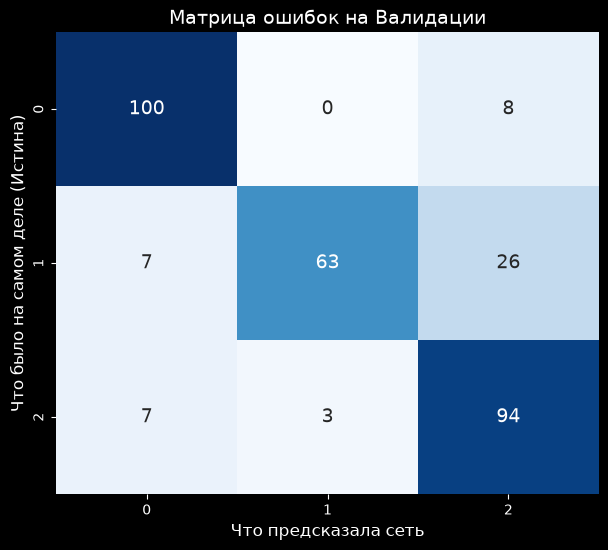

In [ ]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

model.eval()
all_preds = []
all_labels = []

# Отключаем градиенты для ускорения и экономии памяти
with torch.no_grad():
    for batch_x, batch_y in val_dataloader:
        outputs = model(batch_x)
        _, predicted = torch.max(outputs.data, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(batch_y.cpu().numpy())

# Считаем матрицу
cm = confusion_matrix(all_labels, all_preds)

# Отрисовка
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            annot_kws={"size": 14})

plt.xlabel('Что предсказала сеть', fontsize=12)
plt.ylabel('Что было на самом деле (Истина)', fontsize=12)
plt.title('Матрица ошибок на Валидации', fontsize=14)
plt.show()

In [ ]:
import numpy as np

model.eval()
weights = {}

# Вытаскиваем все матрицы весов и смещений из PyTorch
for name, tensor in model.state_dict().items():
    weights[name] = tensor.cpu().numpy()

# Сохраняем в обычный numpy-архив
np.savez('weights.npz', **weights)

✅ Готово! Перекинь файл weights.npz на телефон.
